**Autores:** Jesús Moreno Cruz y Corro

# 3.  Codificación de variables

Conjunto de datos: titanic (incluido en seaborn)

Este conjunto de datos es excelente para trabajar con variables categóricas.

In [1]:
# Importar librerías necesarias
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

In [2]:
# Cargar el conjunto de datos
data = sns.load_dataset('titanic')

In [3]:
# Visualizar las primeras filas
print("Conjunto de datos Titanic:")
data.head()

Conjunto de datos Titanic:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
# Seleccionar columnas categóricas
categorical_cols = ['sex', 'embarked', 'class']

In [5]:
# Codificar con LabelEncoder
label_encoder = LabelEncoder()
data['sex_label'] = label_encoder.fit_transform(data['sex'])

In [6]:
# Codificar con OneHotEncoder
onehot_encoder = pd.get_dummies(data['embarked'], prefix='embarked')

In [7]:
# Combinar con el conjunto original
data = pd.concat([data, onehot_encoder], axis=1)

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado. Crea gráficas en donde veas correcto.

### 1. ¿Qué diferencias encuentras entre LabelEncoder y OneHotEncoder?

In [8]:
# Ejercicio 1: LabelEncoder vs. OneHotEncoder sobre las mismas columnas
print("Codificación de 'sex' con LabelEncoder:")
print(data[['sex', 'sex_label']].drop_duplicates().sort_values('sex_label'))

print("\nCodificación de 'embarked' con OneHot (get_dummies):")
print(pd.get_dummies(data['embarked'], prefix='embarked').head())

Codificación de 'sex' con LabelEncoder:
      sex  sex_label
1  female          0
0    male          1

Codificación de 'embarked' con OneHot (get_dummies):
   embarked_C  embarked_Q  embarked_S
0       False       False        True
1        True       False       False
2       False       False        True
3       False       False        True
4       False       False        True


**Respuesta:**

- **LabelEncoder** asigna un entero a cada categoría (`female` = 0, `male` = 1). Eso sugiere un orden y una distancia entre categorías que no existen en `sex`.
- **OneHotEncoder** (`get_dummies`) crea una columna binaria por categoría, sin orden implícito. El costo es más columnas: `embarked` pasa de 1 columna a 3.

### 2. Crea una gráfica de barras comparando las frecuencias de 'sex' antes y después de la codificación con LabelEncoder.

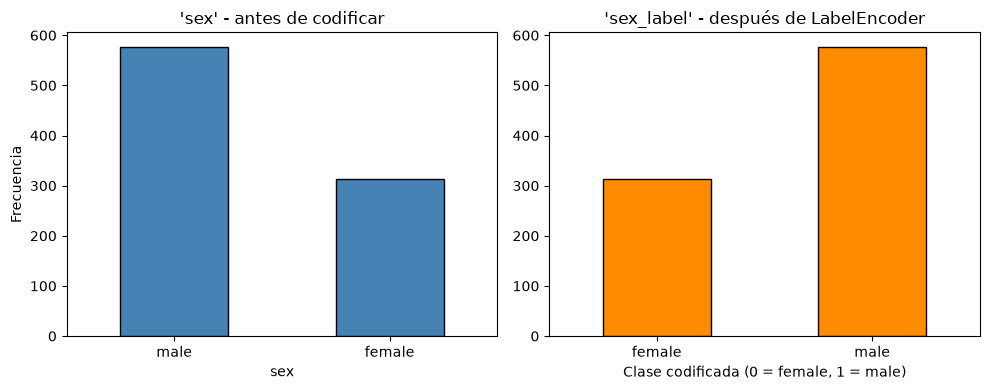

In [9]:
import matplotlib.pyplot as plt

# Ejercicio 2: frecuencias de 'sex' antes y después de LabelEncoder
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))

conteo_original = data['sex'].value_counts()
conteo_original.plot(kind='bar', ax=ejes[0], color='steelblue', edgecolor='black')
ejes[0].set_title("'sex' - antes de codificar")
ejes[0].set_ylabel('Frecuencia')
ejes[0].tick_params(axis='x', rotation=0)

conteo_codificado = data['sex_label'].value_counts().sort_index()
conteo_codificado.plot(kind='bar', ax=ejes[1], color='darkorange', edgecolor='black')
ejes[1].set_title("'sex_label' - después de LabelEncoder")
ejes[1].set_xticklabels(label_encoder.classes_, rotation=0)
ejes[1].set_xlabel('Clase codificada (0 = female, 1 = male)')

plt.tight_layout()
plt.show()

**Respuesta:** las frecuencias son las mismas antes y después de la codificación. LabelEncoder solo cambia las etiquetas (`female`/`male` por 0/1); no altera los conteos.

### 3. Utiliza OneHotEncoder para codificar la columna 'class'. ¿Qué ventajas tiene este enfoque frente a LabelEncoder?

In [10]:
# Ejercicio 3: OneHotEncoder sobre la columna 'class'
onehot_class = OneHotEncoder(sparse_output=False)
clase_codificada = onehot_class.fit_transform(data[['class']])
clase_df = pd.DataFrame(
    clase_codificada,
    columns=onehot_class.get_feature_names_out(['class']),
    index=data.index,
)
print("Categorías detectadas:", list(onehot_class.categories_[0]))
clase_df.head()

Categorías detectadas: ['First', 'Second', 'Third']


,class_First,class_Second,class_Third
0,0.0,0.0,1.0
1,1.0,0.0,0.0
2,0.0,0.0,1.0
3,1.0,0.0,0.0
4,0.0,0.0,1.0


**Respuesta:** OneHotEncoder genera `class_First`, `class_Second` y `class_Third`, cada una con valores 0/1. Ventajas frente a LabelEncoder:

- No impone un orden ni una distancia entre clases.
- Con LabelEncoder, `class` quedaría asignada en orden alfabético (First = 0, Second = 1, Third = 2), que no corresponde al orden real.

Nota: `class` sí tiene un orden natural (1.ª > 2.ª > 3.ª). Si ese orden es relevante para el modelo, una codificación ordinal sería válida; One-Hot lo descarta.

### 4. Si quisieras aplicar un modelo de aprendizaje automático, ¿qué tipo de codificación elegirías para las variables categóricas? Explica tu respuesta.

In [11]:
# Ejercicio 4: número de columnas que produce cada codificación
for col in categorical_cols:
    n_cat = data[col].nunique()
    print(f"{col}: {n_cat} categorías -> LabelEncoder: 1 columna | OneHot: {n_cat} columnas")

sex: 2 categorías -> LabelEncoder: 1 columna | OneHot: 2 columnas
embarked: 3 categorías -> LabelEncoder: 1 columna | OneHot: 3 columnas
class: 3 categorías -> LabelEncoder: 1 columna | OneHot: 3 columnas


**Respuesta:** depende del modelo.

- Para variables nominales (`sex`, `embarked`) elegiría **One-Hot**: evita que el modelo interprete un orden falso. Es la opción más segura para modelos lineales, KNN, SVM y redes neuronales.
- Para `class`, que es ordinal, puedo usar codificación ordinal si el modelo aprovecha el orden.
- Los árboles de decisión toleran LabelEncoder, pero One-Hot sigue siendo segura.
- Con muchas categorías (alta cardinalidad), One-Hot genera demasiadas columnas; en ese caso conviene otra técnica, como target encoding.